In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

import models

In [8]:
# infer the model

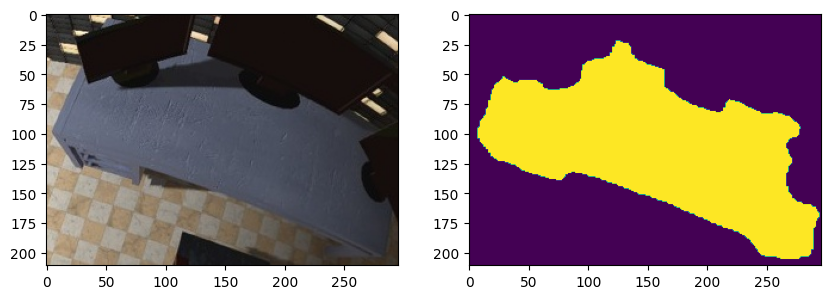

In [60]:
net = models.Segmentator("../fpn/runs/pan_mobilenet_v2_schedule_25_upd_early_stopping/best_upd.onnx")

# 0000251_0
# 269_1, 281_0, 476_2, 617_0, 932_0
# input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000251_0.jpg"), cv2.COLOR_BGR2RGB)
input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000932_0.jpg"), cv2.COLOR_BGR2RGB)
output = net.infer(input_img)
output = np.round(output).astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1,2, 1)
plt.imshow(input_img)
plt.subplot(1, 2, 2)
plt.imshow(output)

In [61]:
# apply morphology

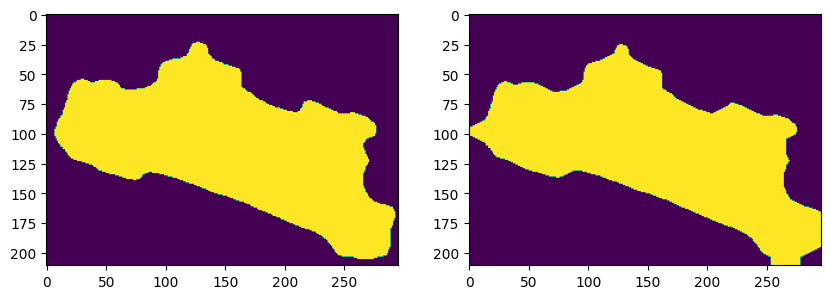

In [62]:
plt.figure(figsize=(10, 5))
k_size = 9
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, k_size))
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))

res = cv2.morphologyEx(output.copy(), cv2.MORPH_OPEN, kernel, iterations=1)
plt.subplot(1, 2, 1)
plt.imshow(res)


k_size = 5
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, k_size))
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))

res = cv2.morphologyEx(res.copy(), cv2.MORPH_CLOSE, kernel, iterations=5)

res = cv2.erode(res, kernel)

plt.subplot(1, 2, 2)
plt.imshow(res)

In [63]:
# get contours

(164, 1, 2)


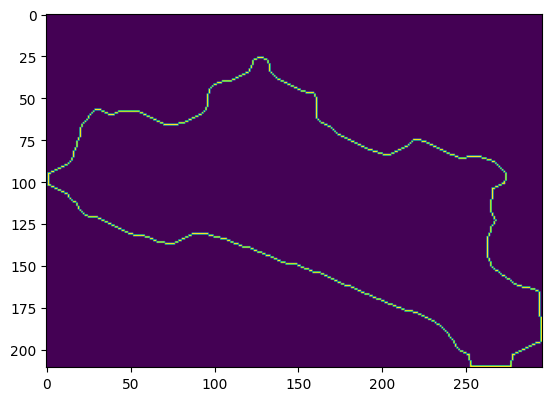

In [64]:
cotour = cv2.findContours(res, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_TC89_L1)
res_contour = cv2.drawContours(res.copy(), cotour[0], 0, (255, 0, 0))
print(cotour[0][0].shape)
plt.imshow(res_contour)

In [65]:
# approx contours

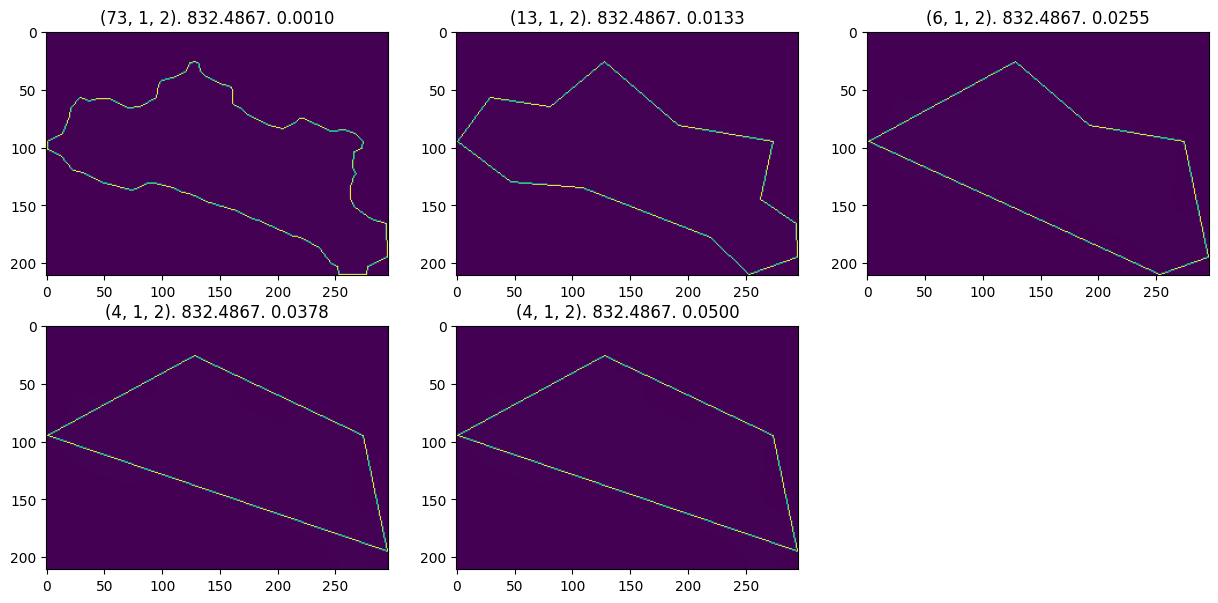

In [84]:
c = cotour[0][0]

plt.figure(figsize=(15, 7))
for idx, eps in enumerate(np.linspace(0.001, 0.05, 5)):
    peri = cv2.arcLength(c, True)
    approx = cv2.approxPolyDP(c, eps * peri, True)

    res_contour = cv2.drawContours(res.copy(), [approx], 0, (255, 0, 0))
    plt.subplot(2, 3, idx + 1)
    plt.imshow(res_contour)
    plt.title(f"{approx.shape}. {peri:.04f}. {eps:.04f}")

In [85]:
min_rect = cv2.minAreaRect(c)
min_rect

((162.68096923828125, 107.19648742675781),
 (310.2602233886719, 126.2688980102539),
 21.223655700683594)

In [95]:
min_rect_rot = cv2.boxPoints(min_rect).astype(int)
min_rect_rot

array([[ -4, 109],
       [ 40,  -7],
       [330, 104],
       [284, 222]])

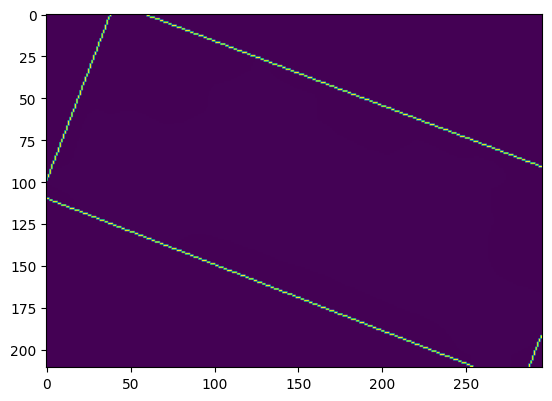

In [98]:
res_contour = cv2.drawContours(res.copy(), [min_rect_rot[:, None, :]], 0, (255, 0, 0))
plt.imshow(res_contour)

# simple approach

In [99]:
# infer the model

Text(0.5, 1.0, '6. final result')

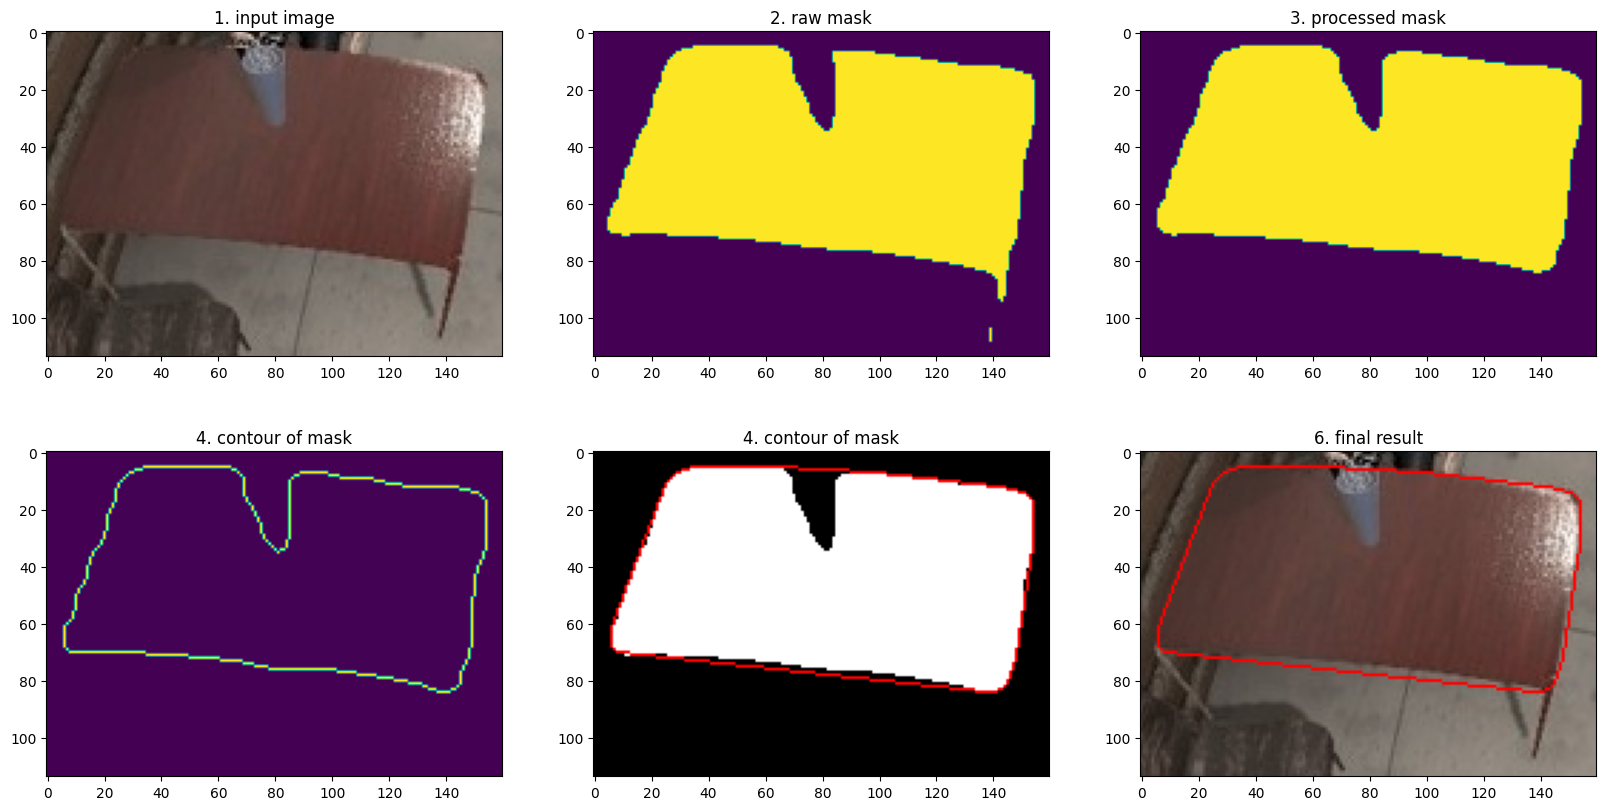

In [196]:
net = models.Segmentator("../fpn/runs/pan_mobilenet_v2_schedule_25_upd_early_stopping/best_upd.onnx")

# segment image
# 0000251_0
# 269_1, 281_0, 476_2, 617_0, 932_0
# input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000251_0.jpg"), cv2.COLOR_BGR2RGB)
input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000281_0.jpg"), cv2.COLOR_BGR2RGB)
output = net.infer(input_img)
output = np.round(output).astype(np.uint8)

# apply morphology
k_size = 11
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, k_size))
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))

res_morphology = cv2.morphologyEx(output.copy(), cv2.MORPH_OPEN, kernel, iterations=1)

# get contours
cotour = cv2.findContours(res_morphology, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_TC89_L1)
res_contour = cv2.drawContours(res_morphology.copy(), cotour[0], 0, (255, 0, 0))

# find convex hull
c = cotour[0][0]
min_rect_rot = cv2.convexHull(c).astype(int)
res_convex = cv2.drawContours(cv2.cvtColor(res * 255, cv2.COLOR_GRAY2RGB).copy(), [min_rect_rot], 0, (255, 0, 0))

res_contour_output = cv2.drawContours(input_img.copy(), [min_rect_rot], 0, (255, 0, 0))

plt.figure(figsize=(20, 10))
plt.subplot(2,3, 1)
plt.imshow(input_img)
plt.title("1. input image")

plt.subplot(2, 3, 2)
plt.imshow(output)
plt.title("2. raw mask")

plt.subplot(2, 3, 3)
plt.imshow(res_morphology)
plt.title("3. processed mask")

plt.subplot(2, 3, 4)
plt.imshow(res_contour)
plt.title("4. contour of mask")

plt.subplot(2, 3, 5)
plt.imshow(res_convex)
plt.title("4. contour of mask")

plt.subplot(2, 3, 6)
plt.imshow(res_contour_output)
plt.title("6. final result")

Text(0.5, 1.0, '6. final result')

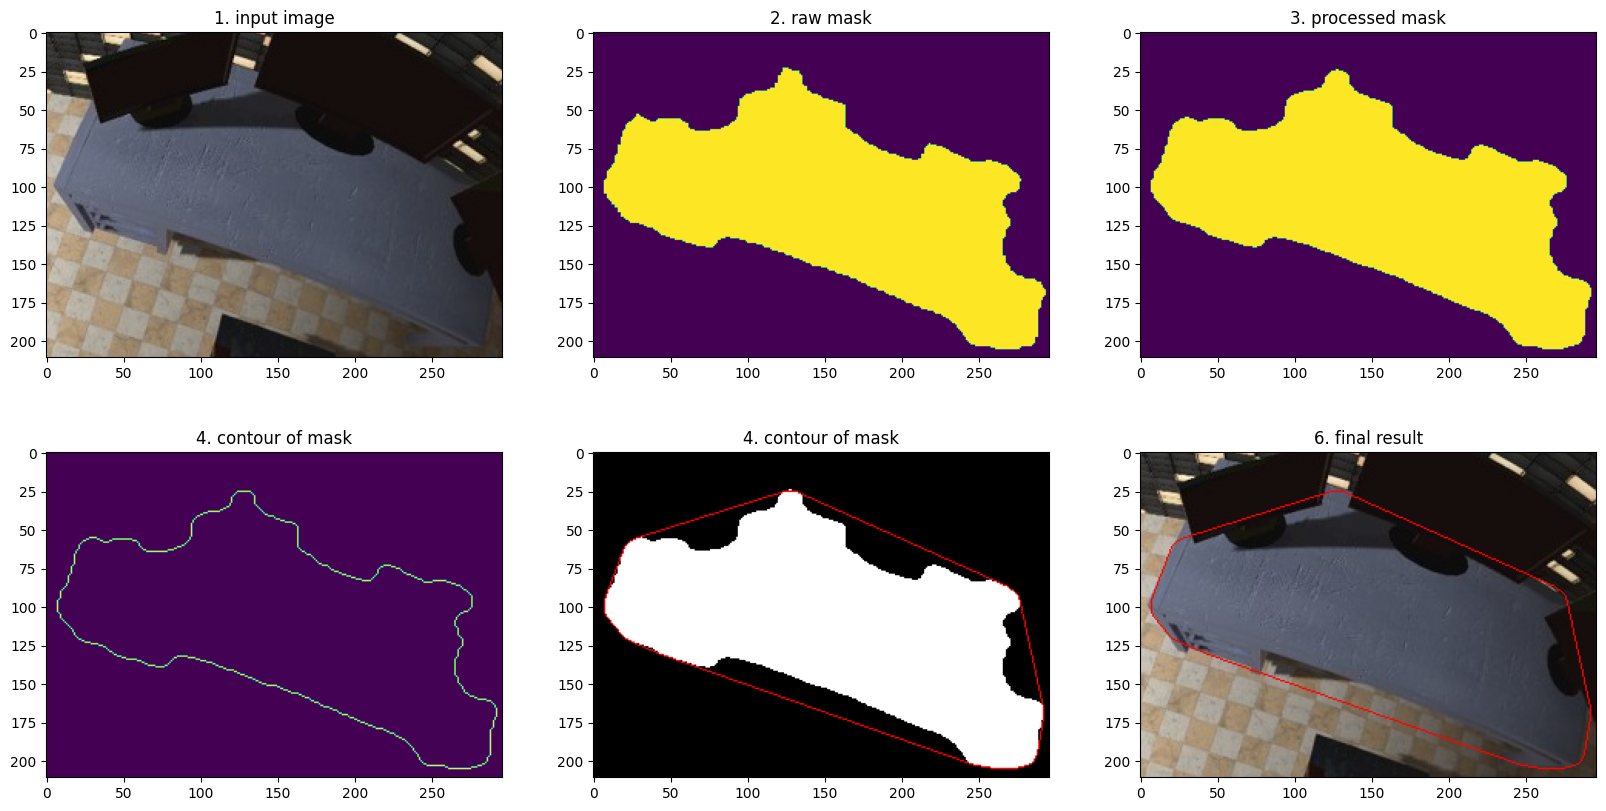

In [200]:
net = models.Segmentator("../fpn/runs/pan_mobilenet_v2_schedule_25_upd_early_stopping/best_upd.onnx")

# segment image
# 0000251_0
# 269_1, 281_0, 476_2, 617_0, 932_0
# input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000251_0.jpg"), cv2.COLOR_BGR2RGB)
input_img = cv2.cvtColor(cv2.imread("../theodore_unet/imgs/0000932_0.jpg"), cv2.COLOR_BGR2RGB)
output = net.infer(input_img)
output = np.round(output).astype(np.uint8)

# apply morphology
k_size = 11
# kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k_size, k_size))
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_size, k_size))

res_morphology = cv2.morphologyEx(output.copy(), cv2.MORPH_OPEN, kernel, iterations=1)

# get contours
cotour = cv2.findContours(res_morphology, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_TC89_L1)
res_contour = cv2.drawContours(res_morphology.copy(), cotour[0], 0, (255, 0, 0))

# find convex hull
c = cotour[0][0]
min_rect_rot = cv2.convexHull(c).astype(int)
res_convex = cv2.drawContours(cv2.cvtColor(res_morphology * 255, cv2.COLOR_GRAY2RGB).copy(), [min_rect_rot], 0, (255, 0, 0))

res_contour_output = cv2.drawContours(input_img.copy(), [min_rect_rot], 0, (255, 0, 0))

plt.figure(figsize=(20, 10))
plt.subplot(2,3, 1)
plt.imshow(input_img)
plt.title("1. input image")

plt.subplot(2, 3, 2)
plt.imshow(output)
plt.title("2. raw mask")

plt.subplot(2, 3, 3)
plt.imshow(res_morphology)
plt.title("3. processed mask")

plt.subplot(2, 3, 4)
plt.imshow(res_contour)
plt.title("4. contour of mask")

plt.subplot(2, 3, 5)
plt.imshow(res_convex)
plt.title("4. contour of mask")

plt.subplot(2, 3, 6)
plt.imshow(res_contour_output)
plt.title("6. final result")